# Part 2: Data Science Basics

**Author:** Enock Niyonkuru · **Questions?** Email [enock.niyonkuru@ucsf.edu](mailto:enock.niyonkuru@ucsf.edu)

In Part 1 you learned the Python language. Now you'll use it on **tables of data**: load a table, clean it, explore it and plot it. These are the everyday skills of a dry-lab biologist, and the first steps of any single-cell analysis.

| Notebook | What you learn |
|---|---|
| 1. Python basics | The language itself |
| **2. Data science (this one)** | **Load, explore and plot tables with pandas** |
| 3. Machine learning | ML concepts and training small models |

Machine-learning models learn from tables of numbers, so in Part 3 you'll hand them tables like the ones you prepare here.

## The dataset: `dummy_cells.csv`
One small, **simulated** file that looks like the cell-level information from a single-cell experiment. Keep it in the same folder as this notebook. (In Colab: click the folder icon in the left sidebar, then upload it.)

It has **600 rows (one per cell)** and **7 columns**. Some `pct_mito` values are blank on purpose, so you can practise handling missing data.

| Column | Meaning |
|---|---|
| `cell_id` | Unique name of the cell |
| `cell_type` | `T cell`, `B cell`, `Monocyte` or `NK cell` |
| `condition` | `control` or `treated` |
| `n_genes` | Number of different genes detected. Very low can mean a poor-quality cell or debris. |
| `total_counts` | Total RNA counts detected (how deeply the cell was sequenced) |
| `pct_mito` | % of counts from mitochondrial genes. High often means a stressed or dying cell. |
| `CD3E` | Count for the gene CD3E, a marker of T cells |

## What you will be able to do
- Load a table from CSV, Excel or Parquet and inspect it.
- Select, filter, sort and add columns, and deal with missing values.
- Summarise groups with `groupby`, and explore data with simple statistics.
- Draw the main plot types: histogram, bar, box, violin, scatter and heatmap.

## How each section works
**Intro** (the idea in plain English), **Let's run it** (short cells to run with Shift + Enter, from top to bottom) and **Try it yourself** (a small exercise). You don't need to memorise anything. Real programmers look things up all the time.

## Contents
1. Introduction to pandas
2. Exploratory data analysis (EDA)
3. Data visualization

Run the cell below first, every time you open this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")    # clean plot style for everything below
print("Ready!")

Ready!


# 1. Introduction to Pandas

**In plain English:** **pandas** is Python's library for tables. A table is called a **DataFrame**, and a single column of it is a **Series**. pandas can read and write CSV, Excel and Parquet files, and filter, sort and summarise data in one line.

**Lab analogy:** A DataFrame is an **Excel sheet with superpowers**. In single-cell data, each **row is a cell** and each **column is something we measured** about it. Instead of clicking around, you write steps that can be re-run on any dataset (repeatable, checkable, and fine for millions of rows).

**Key terms**
- **DataFrame:** a table of rows and columns. We'll call ours `df`.
- **Series:** one column of a DataFrame.
- **CSV:** a plain text file where commas separate the columns.
- **NaN:** how pandas shows a **missing** value.
- **Filtering:** keeping only the rows that meet a condition.

**Watch out for**
- **Run cells in order.** If `df` isn't defined, a cell above was skipped.
- Column names are text, so they need quotes: `df["n_genes"]`.
- To combine filters use `&` (and) / `|` (or), with each condition in its own parentheses.
- Most pandas commands return a **new** table. To keep the change, store it: `df = df.sort_values(...)`.

## Let's run it

**Load a CSV.** `pd.read_csv` turns the file into a DataFrame, and `.head()` shows the first 5 rows. You'll see 7 columns. Notice the `NaN` under `pct_mito` in the first row: a missing value.

In [2]:
df = pd.read_csv("dummy_cells.csv")
df.head()

,cell_id,cell_type,condition,n_genes,total_counts,pct_mito,CD3E
0,cell_0,Monocyte,treated,2149,5432,NaN,1
1,cell_1,B cell,control,2472,4580,3.79,1
2,cell_2,Monocyte,treated,2667,9273,0.59,2
3,cell_3,Monocyte,treated,1895,11812,5.22,0
4,cell_4,T cell,treated,2934,8966,4.87,9


**Other file formats.** Save the table as Excel and Parquet (a compact format for big tables), then read them back. You'll see `(600, 7)` three times, so nothing was lost. (If you get an error about `openpyxl` or `pyarrow`, run `!pip install openpyxl pyarrow`.)

In [3]:
df.to_csv("cells.csv", index=False)         # index=False: don't save the row numbers
df.to_excel("cells.xlsx", index=False)
df.to_parquet("cells.parquet")

print(pd.read_csv("cells.csv").shape)
print(pd.read_excel("cells.xlsx").shape)
print(pd.read_parquet("cells.parquet").shape)

(600, 7)


(600, 7)
(600, 7)


> **Which format?** CSV is universal and readable. Excel is convenient for sharing. **Parquet is fast and compact, so it's preferred for big data.**

**A first look.** Always do this with new data. `.shape` gives (rows, columns), and `.info()` lists each column's type and how many values are *not* missing. In `.info()`, `pct_mito` shows 585 of 600, so 15 values are missing. (`object` means text, `int64` whole numbers, `float64` decimals.)

In [4]:
print(df.shape)
df.info()

(600, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cell_id       600 non-null    object 
 1   cell_type     600 non-null    object 
 2   condition     600 non-null    object 
 3   n_genes       600 non-null    int64  
 4   total_counts  600 non-null    int64  
 5   pct_mito      585 non-null    float64
 6   CD3E          600 non-null    int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 32.9+ KB


**One column (a Series).** You'll see the type, then the mean, max and min of `n_genes`, then its first 5 values.

In [5]:
n_genes = df["n_genes"]
print(type(n_genes))
print(n_genes.mean(), n_genes.max(), n_genes.min())
n_genes.head()

<class 'pandas.core.series.Series'>
2500.7083333333335 4185 310


0    2149
1    2472
2    2667
3    1895
4    2934
Name: n_genes, dtype: int64

**Selecting columns and rows.** Pick several columns (note the double brackets), then rows by position with `.iloc` (the end is excluded).

In [6]:
df[["cell_id", "cell_type"]].head()

,cell_id,cell_type
0,cell_0,Monocyte
1,cell_1,B cell
2,cell_2,Monocyte
3,cell_3,Monocyte
4,cell_4,T cell


In [7]:
df.iloc[0:3]

,cell_id,cell_type,condition,n_genes,total_counts,pct_mito,CD3E
0,cell_0,Monocyte,treated,2149,5432,NaN,1
1,cell_1,B cell,control,2472,4580,3.79,1
2,cell_2,Monocyte,treated,2667,9273,0.59,2


**Filtering.** Keep only rows that meet a condition (`==` means "is equal to"). You'll see the first 5 T cells.

In [8]:
df[df["cell_type"] == "T cell"].head()

,cell_id,cell_type,condition,n_genes,total_counts,pct_mito,CD3E
4,cell_4,T cell,treated,2934,8966,4.87,9
8,cell_8,T cell,control,2492,14239,10.10,13
10,cell_10,T cell,treated,2437,8023,2.94,6
15,cell_15,T cell,control,1796,9824,6.06,6
17,cell_17,T cell,treated,2673,6976,3.99,11


Combine conditions for QC: more than 2000 genes **and** less than 10% mito. Cells with a blank `pct_mito` can't pass, so they are left out.

In [9]:
good = df[(df["n_genes"] > 2000) & (df["pct_mito"] < 10)]
print(f"{len(good)} of {len(df)} cells pass the filter")

378 of 600 cells pass the filter


**New columns, sorting and renaming.** Make two new columns from existing ones (`log1p` is log of 1+x, which squeezes big numbers together and is safe for zeros), then show the 3 cells with the most genes. You'll see two new columns on the right.

In [10]:
df["log_counts"] = np.log1p(df["total_counts"])
df["genes_per_count"] = df["n_genes"] / df["total_counts"]

df.sort_values("n_genes", ascending=False).head(3)

,cell_id,cell_type,condition,n_genes,total_counts,pct_mito,CD3E,log_counts,genes_per_count
209,cell_209,B cell,control,4185,9911,4.54,1,9.201501,0.422258
470,cell_470,B cell,treated,4126,7306,10.31,1,8.896588,0.564741
298,cell_298,Monocyte,control,3974,5958,7.12,0,8.692658,0.667002


Renaming works the same way. Here we *don't* store the result, so `df` keeps its original names. That's the "changes don't stick unless you store them" rule from above.

In [11]:
df.rename(columns={"pct_mito": "percent_mito"}).head(2)    # df itself is unchanged

,cell_id,cell_type,condition,n_genes,total_counts,percent_mito,CD3E,log_counts,genes_per_count
0,cell_0,Monocyte,treated,2149,5432,NaN,1,8.600247,0.395619
1,cell_1,B cell,control,2472,4580,3.79,1,8.429673,0.539738


**Missing values.** Count them, fill them with the column's median (the middle value), then count again. You'll see 15 for `pct_mito`, then `Missing now: 0`. Filling is a choice, not a rule. Dropping the rows with `df.dropna()` is another option.

In [12]:
print(df.isna().sum())

df["pct_mito"] = df["pct_mito"].fillna(df["pct_mito"].median())
print("Missing now:", df["pct_mito"].isna().sum())

cell_id             0
cell_type           0
condition           0
n_genes             0
total_counts        0
pct_mito           15
CD3E                0
log_counts          0
genes_per_count     0
dtype: int64
Missing now: 0


**Group and summarise** is the most useful trick. `groupby` splits the table into groups and calculates something for each. Here: the average `n_genes` per cell type.

In [13]:
df.groupby("cell_type")["n_genes"].mean()

cell_type
B cell      2568.804878
Monocyte    2449.755435
NK cell     2427.072727
T cell      2521.924370
Name: n_genes, dtype: float64

Group by two columns and calculate several things at once. You'll see 8 groups (4 cell types x 2 conditions).

In [14]:
df.groupby(["cell_type", "condition"]).agg(
    n_cells=("cell_id", "count"),
    mean_genes=("n_genes", "mean"),
    mean_mito=("pct_mito", "mean"),
).round(1)

n_cells  mean_genes  mean_mito
cell_type condition                                
B cell    control         64      2543.7        6.6
          treated         59      2596.1        6.5
Monocyte  control         84      2522.2        6.0
          treated        100      2388.9        6.8
NK cell   control         25      2474.8        4.6
          treated         30      2387.3        7.2
T cell    control        128      2505.5        6.4
          treated        110      2541.1        5.4

**Count categories.** `value_counts()` tells you how many of each value there are, and whether your groups are balanced.

In [15]:
df["cell_type"].value_counts()

cell_type
T cell      238
Monocyte    184
B cell      123
NK cell      55
Name: count, dtype: int64

## Try it yourself
1. How many **Monocytes** are in the **treated** condition? (**Hint:** two conditions joined with `&`, then `len(...)`.)
2. Add a column `high_quality` that is `True` when `n_genes > 2500`.
3. What is the average `total_counts` for each `condition`? (Use `groupby`.)

In [ ]:
# Task 1: treated Monocytes
# Copy the shape of the "good" filter above: two conditions, each in ( ), joined with &
# mono_treated = df[(df["cell_type"] == "Monocyte") & (df["condition"] == ___)]
# print(len(mono_treated))               # check against the crosstab in Section 2

# Task 2: new True/False column
# df["high_quality"] = df["n_genes"] > ___
# df.head()

# Task 3: average total_counts per condition
# Copy the shape of: df.groupby("cell_type")["n_genes"].mean()
# df.groupby(___)["total_counts"].mean()

# 2. Exploratory Data Analysis (EDA)

**In plain English:** EDA means **getting to know your data before you trust it**. How big is it? What's missing? Are there strange values? You use summary numbers, counts and comparisons to find out.

**Lab analogy:** Before an experiment you check your reagents and that the cells look healthy. EDA is the same sanity check for data. Skipping it is the most common reason analyses fail, because a model will happily learn from a broken batch.

**Key terms**
- **Mean / median:** the average / the middle value. The median is less affected by extreme values.
- **Quantile:** the value below which a given fraction of the data falls (0.5 = the median).
- **Outlier:** a value far from the rest. It could be real biology or a problem, like a dying cell.
- **Correlation:** a number from -1 to 1 showing how closely two columns rise and fall together.
- **QC (quality control):** removing data that is too poor to trust, such as cells with too few genes.

**Watch out for**
- Don't trust the mean alone. Compare it with the median, min and max.
- Correlation is not cause.
- Don't delete outliers without a reason, and write the rule in code so it can be repeated.
- Check for missing values first, because they silently change your counts and averages.

## Let's run it

**Summary statistics.** `describe()` summarises the number columns (count, mean, spread, min, quartiles, max). Read them slowly and ask: do these look sensible?

In [17]:
df.describe().round(2)

,n_genes,total_counts,pct_mito,CD3E,log_counts,genes_per_count
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,2500.71,8648.66,6.23,3.67,9.02,0.32
std,610.33,2506.63,4.43,3.86,0.33,0.18
min,310.00,1380.00,0.09,0.00,7.23,0.03
25%,2119.75,7032.50,2.98,1.00,8.86,0.23
50%,2511.00,8767.50,5.37,2.00,9.08,0.29
75%,2891.00,10358.50,8.23,7.00,9.25,0.37
max,4185.00,16285.00,28.68,17.00,9.70,2.61


In [18]:
df.describe(include="object")    # the same, for text columns

,cell_id,cell_type,condition
count,600,600,600
unique,600,4,2
top,cell_0,T cell,control
freq,1,238,301


**Outliers.** A cell with very high mitochondrial % may be dying. Count how many are above 15%, then look at the spread of `total_counts` with `quantile` (0 = min, 0.5 = median, 1 = max).

In [19]:
print((df["pct_mito"] > 15).sum(), "cells with more than 15% mito")
df["total_counts"].quantile([0, 0.25, 0.5, 0.75, 0.95, 1])

27 cells with more than 15% mito


0.00     1380.0
0.25     7032.5
0.50     8767.5
0.75    10358.5
0.95    12693.1
1.00    16285.0
Name: total_counts, dtype: float64

**Correlation.** A table of correlations between all number columns. The diagonal is 1.00 (each column matches itself), and `log_counts` is close to 1 with `total_counts` because it was calculated from it.

In [20]:
df.select_dtypes("number").corr().round(2)

,n_genes,total_counts,pct_mito,CD3E,log_counts,genes_per_count
n_genes,1.00,0.04,0.05,0.01,0.04,0.44
total_counts,0.04,1.00,-0.07,0.03,0.97,-0.67
pct_mito,0.05,-0.07,1.00,-0.03,-0.08,0.09
CD3E,0.01,0.03,-0.03,1.00,0.05,-0.05
log_counts,0.04,0.97,-0.08,0.05,1.00,-0.77
genes_per_count,0.44,-0.67,0.09,-0.05,-0.77,1.00


*Note:* `n_genes` and `total_counts` aren't correlated here only because the data is simulated. In real data they usually are.

**Comparing groups.** `crosstab` counts cells for every combination (is the experiment balanced?). Then rank cell types by average `CD3E`. T cells should be far higher, which fits with CD3E being a T cell marker.

In [21]:
pd.crosstab(df["cell_type"], df["condition"])

condition,control,treated
cell_type,,
B cell,64,59
Monocyte,84,100
NK cell,25,30
T cell,128,110


In [22]:
df.groupby("cell_type")["CD3E"].mean().sort_values(ascending=False)

cell_type
T cell      7.764706
Monocyte    1.021739
B cell      0.943089
NK cell     0.909091
Name: CD3E, dtype: float64

**A mini QC pipeline as a function** (from Part 1). `qc_filter` keeps cells with enough genes and not too much mito, and reports how many it kept. We run it twice: default settings, then stricter ones.

In [23]:
def qc_filter(data, min_genes=500, max_mito=20):
    """Keep cells with at least min_genes genes and at most max_mito % mito."""
    keep = (data["n_genes"] >= min_genes) & (data["pct_mito"] <= max_mito)
    print(f"Keeping {keep.sum()} / {len(data)} cells")
    return data[keep].copy()

clean = qc_filter(df)                                # default settings
clean = qc_filter(df, min_genes=2000, max_mito=10)   # stricter

Keeping 589 / 600 cells
Keeping 391 / 600 cells


## Try it yourself
1. Which `cell_type` has the **highest median** `pct_mito`? (**Hint:** `groupby`, then `.median()`, then `.sort_values()`.)
2. Find the **5 cells with the most `total_counts`**.
3. Run `qc_filter` with your own thresholds. How many cells remain?

In [ ]:
# Task 1: highest median pct_mito
# Group by cell type, take the median, then sort from biggest to smallest
# df.groupby("cell_type")["pct_mito"].___().sort_values(ascending=False)

# Task 2: top 5 cells by total_counts
# Sort with the biggest first, then show the first 5 rows
# df.sort_values(___, ascending=False).head(5)

# Task 3: your own QC thresholds
# Pick your own numbers, e.g. at least 1000 genes and at most 15% mito
# my_clean = qc_filter(df, min_genes=___, max_mito=___)

# 3. Data Visualization

**In plain English:** Plots turn numbers into pictures. Each type answers a different question:

| Question | Plot |
|---|---|
| What does one variable look like? | **Histogram** |
| How many in each category? | **Bar chart** |
| How does a number differ between groups? | **Box** or **violin** plot |
| Are two numbers related? | **Scatter plot** |
| Where are the high and low values in a table? | **Heatmap** |

**Lab analogy:** Plots are the **microscope images of your data**. You wouldn't describe a tissue only by its weight, so don't describe a dataset only by its average. Like a gel image, a plot always needs labels.

**Key terms**
- **Distribution:** how a column's values are spread out.
- **Bin:** one bar of a histogram (a small range of values).
- **Hue:** a seaborn option that colours points by a column.

**Watch out for**
- Always add a title and axis labels, or nobody else can read your plot.
- A pattern in a plot is a hint, not proof.
- Pick the right chart for the question (see the table above).

## Let's run it

**Histogram.** Splits the range into bins and counts the cells in each. Look at where most cells sit and whether any sit far away.

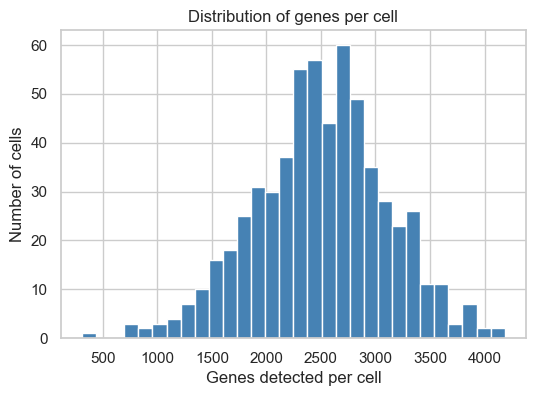

In [25]:
plt.figure(figsize=(6, 4))
plt.hist(df["n_genes"], bins=30, color="steelblue", edgecolor="white")
plt.xlabel("Genes detected per cell")
plt.ylabel("Number of cells")
plt.title("Distribution of genes per cell")
plt.show()

**Bar chart.** One bar per cell type, matching the counts you saw earlier.

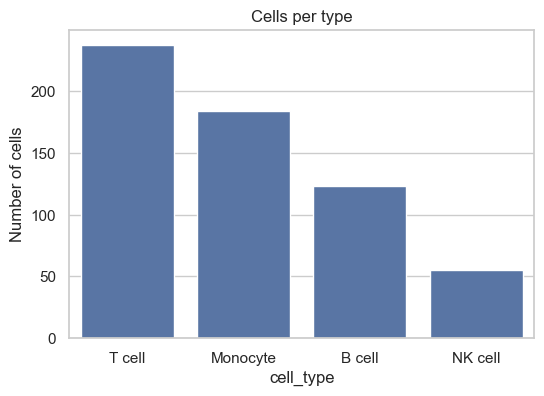

In [26]:
counts = df["cell_type"].value_counts()

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.ylabel("Number of cells")
plt.title("Cells per type")
plt.show()

**Box and violin plots.** Both compare a measurement across groups. In a box plot, the line is the median, the box covers the middle half, and dots are possible outliers. A violin shows the full shape. Notice how the T cell violin for CD3E sits higher.

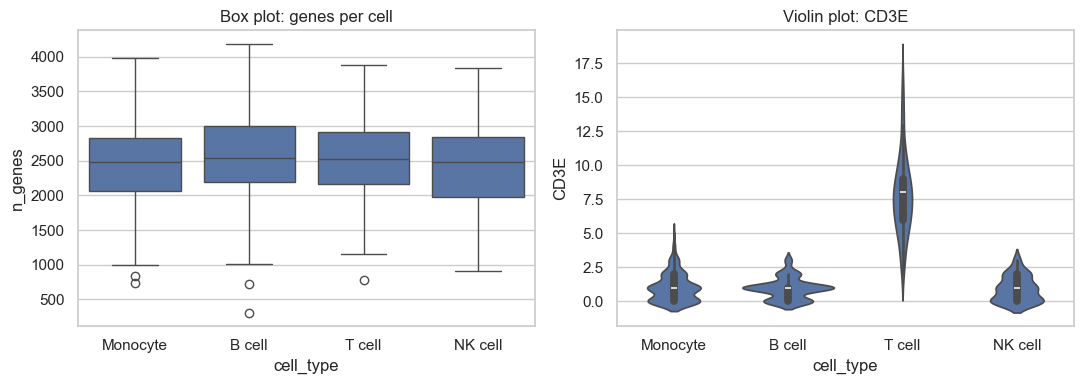

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))    # 1 row, 2 plots side by side

sns.boxplot(data=df, x="cell_type", y="n_genes", ax=ax[0])
ax[0].set_title("Box plot: genes per cell")

sns.violinplot(data=df, x="cell_type", y="CD3E", ax=ax[1])
ax[1].set_title("Violin plot: CD3E")

plt.tight_layout()
plt.show()

**Scatter plot.** One dot per cell. Here the two columns are almost unrelated (simulated data), so expect a cloud, not a line.

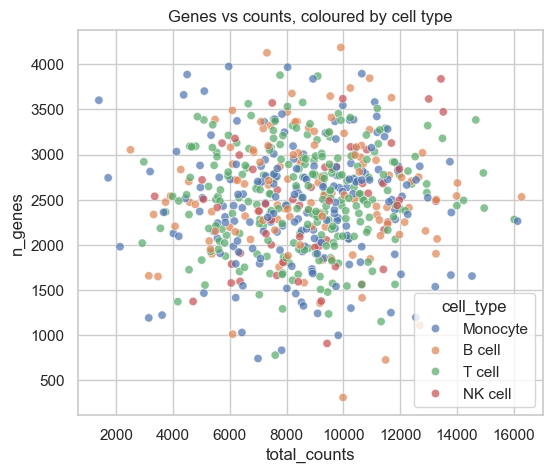

In [28]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x="total_counts", y="n_genes", hue="cell_type", alpha=0.7)
plt.title("Genes vs counts, coloured by cell type")
plt.show()

**Heatmap.** First build a small table of the average CD3E per cell type and condition, then show it as colours. Brighter yellow is higher, so the T cell row should stand out.

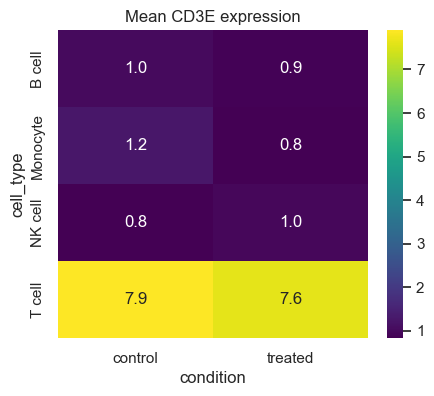

In [29]:
pivot = df.pivot_table(index="cell_type", columns="condition", values="CD3E", aggfunc="mean")

plt.figure(figsize=(5, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="viridis")    # annot=True writes the numbers
plt.title("Mean CD3E expression")
plt.show()

**Putting it together: a QC panel.** A `for` loop (from Part 1) draws a histogram for each of three QC columns, then saves the figure as `qc_panel.png`. Panels like this are a standard first look at any sequencing run.

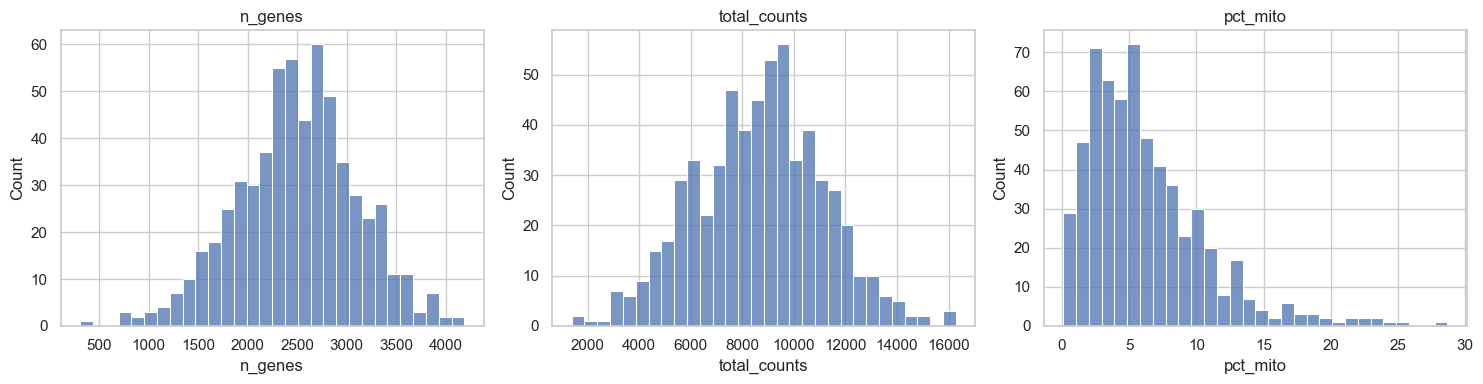

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["n_genes", "total_counts", "pct_mito"]):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.savefig("qc_panel.png", dpi=150)     # save for slides or papers
plt.show()

## Try it yourself
1. Make a **violin plot** of `pct_mito` split by `condition`.
2. Make a **scatter plot** of `n_genes` vs `pct_mito`, coloured by `condition`. Do cells with high mito have fewer genes?
3. Give both a title and axis labels.

**Hint:** `sns.violinplot(data=df, x="...", y="...")`, and finish with `plt.show()`.

In [ ]:
# Task 1: violin plot of pct_mito per condition
# Copy the violin example above and swap the column names
# plt.figure(figsize=(6, 4))
# sns.violinplot(data=df, x=___, y=___)
# plt.title("___")
# plt.xlabel("___"); plt.ylabel("___")
# plt.show()

# Task 2: scatter of n_genes vs pct_mito, coloured by condition
# Copy the scatter example above; change x, y and hue
# plt.figure(figsize=(6, 5))
# sns.scatterplot(data=df, x="n_genes", y=___, hue=___, alpha=0.7)
# plt.title("___")
# plt.show()

# Part 2 complete!

## Quick recap
- **pandas** holds tables as DataFrames (one column is a Series). You can load and save CSV, Excel and Parquet.
- You **selected, filtered, sorted and grouped** data, added columns, and handled **missing values**.
- **EDA** (summary stats, outliers, correlations, group comparisons) is how you get to know your data and choose QC thresholds.
- You drew **histograms, bar charts, box and violin plots, scatter plots and heatmaps**.

## Next
1. Finish any "Try it yourself" you skipped.
2. Try it on your own data: export a small table from an experiment as a CSV, load it, and run `.shape`, `.info()` and `.head()`.
3. Open **`03_Intro_to_Machine_Learning.ipynb`**.